In [5]:
import numpy as np
import pandas as pd
import time
import os
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('data/listings.csv')
df['dom'] = df['days_on_market']
df['remarks_len'] = df['remarks'].astype(str).str.len()
df['remarks_len'].max()
df_500 = df.loc[df['remarks_len']>700]
df_500['bedrooms'].mean(), df_500['washrooms'].mean(), df_500['house_style'].value_counts()

(np.float64(2.72),
 np.float64(2.624),
 house_style
 2-Storey           87
 Apartment          72
 Bungalow           29
 3-Storey           20
 2 1/2 Storey       16
 Stacked Townhse     6
 Bungalow-Raised     5
 Multi-Level         5
 1 1/2 Storey        3
 Sidesplit 4         3
 Backsplit 4         2
 Backsplit 3         1
 Loft                1
 Name: count, dtype: int64)

In [28]:
df['bedrooms'].mean(), df['washrooms'].mean(), df['house_style'].value_counts()

(np.float64(2.3416733333333335),
 np.float64(2.1583133333333335),
 house_style
 Apartment          72455
 2-Storey           36357
 Bungalow           13675
 3-Storey            8962
 2 1/2 Storey        3117
 Stacked Townhse     2613
 Loft                2538
 Bungalow-Raised     2477
 1 1/2 Storey        2247
 Multi-Level         1519
 Backsplit 4         1395
 Sidesplit 4          928
 Backsplit 3          805
 Sidesplit 3          574
 Backsplit 5          320
 1 Storey/Apt          18
 Name: count, dtype: int64)

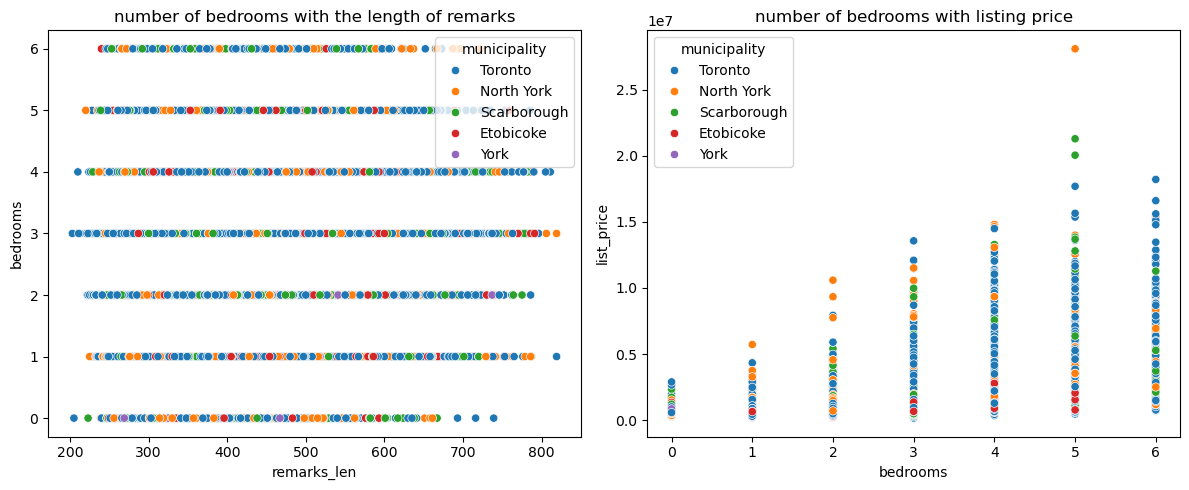

In [6]:
fig, axes = plt.subplots(1,2, figsize = (12,5))
sns.scatterplot(data = df, x = 'remarks_len', y = 'bedrooms', hue = 'municipality', ax = axes[0])
axes[0].set_title("number of bedrooms with the length of remarks")
sns.scatterplot(data = df, x = 'bedrooms', y = 'list_price', hue = 'municipality', ax = axes[1])
axes[1].set_title("number of bedrooms with listing price")
plt.tight_layout()
plt.show()

In [ ]:
df.loc[(df['remarks_len']>700) & (df['bedrooms'] == 0)]

,ml_num,sold_price,list_price,date_listed,date_sold,days_on_market,house_type_name,house_style,bedrooms,washrooms,...,lot_front,lot_depth,municipality,community,latitude,longitude,external_avm_estimate,external_avm_estimate_date,remarks,remarks_len
105637,SYN-0060345,685200.0,782700.0,2024-05-24,2024-06-09,16,Condo Apt,Apartment,0,1,...,NaN,NaN,Toronto,Willowpark,43.646847,-79.336607,709500.0,2024-07-24,Willowpark presents a generously sized studio ...,716
110457,SYN-0143960,417300.0,447200.0,2024-07-25,2024-08-25,31,Condo Apt,Apartment,0,1,...,NaN,NaN,Toronto,Sumacdale,43.566635,-79.340249,426000.0,2024-12-20,An unobstructed view sets the tone for this co...,739


In [12]:
df.loc[df['ml_num'] == 'SYN-0060345', ['sold_price', 'dom', 'house_area']],
df.loc[df['ml_num'] == 'SYN-0143960', ['sold_price', 'dom', 'house_area']]


,sold_price,dom,house_area
110457,417300.0,31,383


In [13]:
print(df.loc[df['ml_num'] == 'SYN-0060345', 'remarks'].iloc[0])
print(df.loc[df['ml_num'] == 'SYN-0143960', 'remarks'].iloc[0])


Willowpark presents a generously sized studio of about 740 square feet, offering the kind of open floor plan that invites you to reimagine the space. The kitchen and bathrooms are original and will need replacing, and the electrical system is dated, so this suite is offered as-is for a buyer ready to take on a project. The building includes guest suites, which add a layer of convenience. Transit and schools are nearby, making the location practical. This is a home for anyone who wants more space and is willing to invest in its potential. It is a blank canvas with good bones and a solid footprint. The right vision will transform this into something special. A rare opportunity to create exactly what you want.
An unobstructed view sets the tone for this compact studio at Ash Drive in Sumacdale, where the city unfolds beyond generous windows. The space, though modest at about 383 square feet, offers a clean slate for a discerning buyer. The bathroom, however, requires a full redo, and the 

In [20]:
train_df = pd.read_csv('data/listings.csv')
val_df = pd.read_csv('data/test_list_aware.csv')

x = str('ml_num,sold_price,list_price,date_listed,date_sold,days_on_market,house_type_name,house_style,bedrooms,washrooms,parking_total,garage,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,external_avm_estimate,external_avm_estimate_date,remarks')
y = str('ml_num,list_price,date_listed,house_type_name,house_style,bedrooms,washrooms,parking_total,garage,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,remarks')

len(x.split(',')), x.split(','),len(y.split(',')), y.split(',')


(22,
 ['ml_num',
  'sold_price',
  'list_price',
  'date_listed',
  'date_sold',
  'days_on_market',
  'house_type_name',
  'house_style',
  'bedrooms',
  'washrooms',
  'parking_total',
  'garage',
  'house_area',
  'lot_front',
  'lot_depth',
  'municipality',
  'community',
  'latitude',
  'longitude',
  'external_avm_estimate',
  'external_avm_estimate_date',
  'remarks'],
 17,
 ['ml_num',
  'list_price',
  'date_listed',
  'house_type_name',
  'house_style',
  'bedrooms',
  'washrooms',
  'parking_total',
  'garage',
  'house_area',
  'lot_front',
  'lot_depth',
  'municipality',
  'community',
  'latitude',
  'longitude',
  'remarks'])